# Assignment 2: Email Spam Classification
Dataset: [Email Spam Classification Dataset (Kaggle)](https://www.kaggle.com/datasets/balaka18/email-spam-classification-dataset-csv)

Binary classification (0 = Not Spam, 1 = Spam) using K-Nearest Neighbors and Support Vector Machine, with a performance comparison.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## Load the dataset

In [2]:
df = pd.read_csv("emails.csv")
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("email no")], errors="ignore")
df.head()

,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,0,0,1,0,0,0,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,8,13,24,6,6,2,102,1,27,18,...,0,0,0,0,0,0,0,1,0,0
2,0,0,1,0,0,0,8,0,0,4,...,0,0,0,0,0,0,0,0,0,0
3,0,5,22,0,5,1,51,2,10,1,...,0,0,0,0,0,0,0,0,0,0
4,7,6,17,1,5,2,57,0,9,3,...,0,0,0,0,0,0,0,1,0,0


In [3]:
print(df.shape)
df["Prediction"].value_counts()

(5172, 3001)


Prediction
0    3672
1    1500
Name: count, dtype: int64

## Train/test split

In [4]:
X = df.drop(columns=["Prediction"])
y = df["Prediction"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Scale features

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## K-Nearest Neighbors

KNN accuracy: 0.8338

              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035



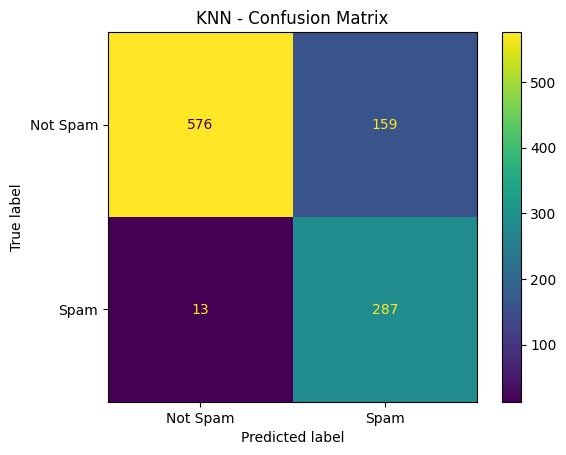

In [6]:
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train)
knn_preds = knn.predict(X_test_scaled)
knn_acc = accuracy_score(y_test, knn_preds)

print(f"KNN accuracy: {knn_acc:.4f}\n")
print(classification_report(y_test, knn_preds, target_names=["Not Spam", "Spam"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, knn_preds), display_labels=["Not Spam", "Spam"]).plot()
plt.title("KNN - Confusion Matrix")
plt.show()

## Support Vector Machine

SVM accuracy: 0.9304

              precision    recall  f1-score   support

    Not Spam       0.91      0.99      0.95       735
        Spam       0.98      0.77      0.87       300

    accuracy                           0.93      1035
   macro avg       0.95      0.88      0.91      1035
weighted avg       0.93      0.93      0.93      1035



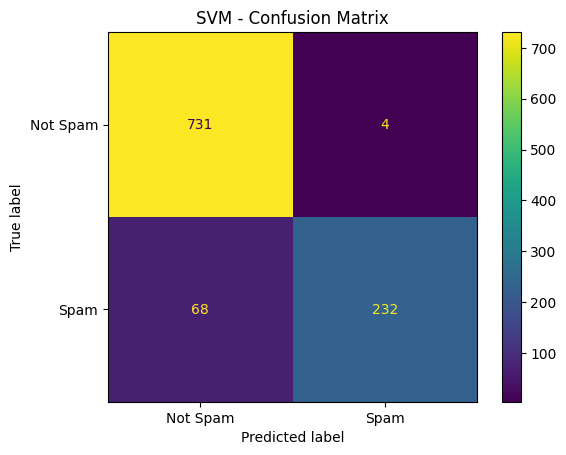

In [7]:
svm = SVC(kernel="rbf", random_state=42).fit(X_train_scaled, y_train)
svm_preds = svm.predict(X_test_scaled)
svm_acc = accuracy_score(y_test, svm_preds)

print(f"SVM accuracy: {svm_acc:.4f}\n")
print(classification_report(y_test, svm_preds, target_names=["Not Spam", "Spam"]))
ConfusionMatrixDisplay(confusion_matrix(y_test, svm_preds), display_labels=["Not Spam", "Spam"]).plot()
plt.title("SVM - Confusion Matrix")
plt.show()

## Performance comparison

In [8]:
pd.DataFrame([
    {"Model": "KNN", "Accuracy": knn_acc},
    {"Model": "SVM", "Accuracy": svm_acc},
])

,Model,Accuracy
0,KNN,0.833816
1,SVM,0.930435
